# NB4 — Sensor baselines: pyranometer QC, night offset, monthly calibration, and the satellite index

Guide §2 step 8, §4.2, D10, D19, D20, D32. Reads `results/nb2_panel/`, `results/nb3_index/` (frozen configuration part 1), the 1-min pyranometer and CAMS all-sky GHI; writes `results/nb4_sensor/`.

**Information set.** The pyranometer and the satellite feed only the baselines A4, A4b, A4c, A9 and A9n, never the main model. This notebook reads donor power and the power of the 10 validation units; it never reads a test-event target (guard in `sensor.validation_by_source`). Every step is causal except the same-month calibration, a labelled sensitivity run.

**Settings fixed before any number below (guide §4.2, D32):**
1. *Time base*: each source is aligned to the panel clock by the whole-minute lag that maximises the correlation of its within-day 5-min changes with those of the NB2 fleet index (all days).
2. *Physical limits* (BSRN): readings below −2 W/m² are removed; the upper limit 1.2 S0 cos(z)^1.2 + 50 W/m² is applied to the calibrated value.
3. *Night offset*: median at solar elevation below −6° over the 7 previous days (at least 360 night minutes, otherwise the last value is kept).
4. *Dead days*: daily sensor irradiation below 3% of clear sky (elevation above 10°, at least 300 minutes); a sensor-only rule.
5. *Clear-sky detection*: pvlib `detect_clearsky` with its defaults, one calendar month per call.
6. *Calibration*: c = median of G_cs / G′ over clear minutes with zenith below 70°; valid with at least 120 minutes and 0.5 ≤ c ≤ 2; month m applies the latest valid earlier month.
7. *15-min values*: mean of at least 10 valid minutes; k = G / G_cs at the panel slot, missing where G̃ ≤ 0.05; bounded to [0, 1.5] except the raw sensor (A4).
8. *Donor gains* refitted against each source with the frozen gain-fit rule (k_min, window, flags) on a 0.3–3.0 grid, without renormalisation; prior = the frozen variant, with G0 = the median donor gain for the metadata-error targets.

In [1]:
import sys, time, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd, yaml
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src'))
from pvcold import config as C, audit as A, fleet as F, sensor as S
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
t0 = time.time()
p = F.load_panel(); del p['targets15_kW']            # no target series is needed in this notebook
E = p['events']; U = p['units']
ALT = json.loads((C.RESULTS / 'nb1_audit' / 'summary.json').read_text())['campus_altitude_m']
nb3 = json.loads((C.RESULTS / 'nb3_index' / 'summary.json').read_text())
FROZEN1_TEXT = (C.RESULTS / 'nb3_index' / 'frozen_config_part1.yaml').read_bytes().decode('utf-8')
assert hashlib.sha256(FROZEN1_TEXT.encode()).hexdigest() == nb3['frozen1_sha256'], 'frozen part 1 changed'
frozen1 = yaml.safe_load(FROZEN1_TEXT)
K_MIN, PRIOR = frozen1['gain_fit']['k_min'], frozen1['prior_variant']
BOUNDARY = pd.Timestamp(frozen1['drift_boundary'])
grid = S.minute_grid(); grid_ext = S.minute_grid(S.MARGIN_MIN)
G = S.load_sensor(grid); cams = S.load_cams(grid)
G_cams = cams['GHI'].where(cams['Reliability'] >= 1)
k5 = pd.read_parquet(C.RESULTS / 'nb2_panel' / 'k_crude5.parquet').set_index('time')['k_crude']
geo_ext = S.minute_geometry(grid_ext, 0.5, ALT)        # geometry at label + 0.5 min (start-labelled minutes)
geo0 = geo_ext.reindex(grid)
print('frozen part 1', nb3['frozen1_sha256'][:12], '| k_min', K_MIN, '| prior', PRIOR, '| boundary', BOUNDARY.date())
print('sensor minutes present: %d of %d; CAMS minutes with reliability < 1: %d' % (G.notna().sum(), len(grid), int((cams['Reliability'] < 1).sum())))
print('setup %.0f s' % (time.time() - t0))

frozen part 1 cb671b7f6713 | k_min 0.3 | prior G2 | boundary 2023-02-17
sensor minutes present: 1567792 of 1576800; CAMS minutes with reliability < 1: 65128
setup 32 s


## 1. Time base of the sensor and of CAMS (D32)
The guide's clear-day method (§2 step 1) comes first: for one sensor its correlation is almost flat over ±6 min. Cloud transitions then time each source directly against the fleet clock (lag L: the fleet value stamped s matches the source minutes labelled [s + L, s + L + 5)).

In [2]:
cds = S.clear_day_scan(G, geo0, ALT)
print('clear-day correlation by shift (rows: year):'); print(cds.pivot(index='year', columns='shift_min', values='corr').round(4).to_string())
scan_s = S.lag_scan(G, geo0['G_cs'], k5); scan_c = S.lag_scan(G_cams, geo0['G_cs'], k5)
periods = ['all'] + sorted(set(scan_s['period']) - {'all'})
lag_tab = pd.DataFrame({'sensor': {q: S.peak_lag(scan_s, q) for q in periods}, 'cams': {q: S.peak_lag(scan_c, q) for q in periods}})
LAG_S, LAG_C = int(round(lag_tab.loc['all', 'sensor'])), int(round(lag_tab.loc['all', 'cams']))
print(lag_tab.round(2).T.to_string())
pk = lambda sc: sc.loc[sc['period'] == 'all', 'corr'].max()
print('sensor lag %+d min (peak corr %.3f) | CAMS lag %+d min (peak corr %.3f)' % (LAG_S, pk(scan_s), LAG_C, pk(scan_c)))

clear-day correlation by shift (rows: year):
shift_min    -6.0    -5.0    -4.0    -3.0    -2.0    -1.0     0.0     1.0     2.0     3.0     4.0     5.0     6.0
year                                                                                                             
2021       0.9586  0.9611  0.9635  0.9658  0.9679  0.9698  0.9716  0.9733  0.9748  0.9761  0.9773  0.9784  0.9792
2022       0.9725  0.9742  0.9756  0.9770  0.9782  0.9793  0.9803  0.9811  0.9818  0.9824  0.9828  0.9831  0.9833
2023       0.9712  0.9729  0.9745  0.9761  0.9775  0.9788  0.9800  0.9810  0.9820  0.9828  0.9836  0.9842  0.9847


         all  2021Q2  2021Q3  2021Q4  2022Q1  2022Q2  2022Q3  2022Q4  2023Q1  2023Q2  2023Q3  2023Q4
sensor -3.32   -3.46   -3.88   -3.69   -3.42   -3.30   -3.30   -3.62   -3.39   -2.86   -2.94   -2.67
cams   -5.02   -5.71   -5.22   -1.92   -2.86   -5.24   -5.25   -1.00   -0.74   -4.66   -4.63   -1.38
sensor lag -3 min (peak corr 0.393) | CAMS lag -5 min (peak corr 0.166)


## 2. Sensor QC, night offset, clear-sky detection and calibration (guide §4.2 steps 1–4)

In [3]:
geo_s = S.shifted_geometry(geo_ext, grid, LAG_S)        # sensor minute tau sits at panel time tau - lag
day = grid.normalize()
dd = S.dead_days(G, geo_s)
no = S.night_offset(G, geo_s)
dead_min = dd['dead'].reindex(day).to_numpy()
Gp = pd.Series(G.to_numpy() - no['offset'].reindex(day).to_numpy(), index=grid)
Gp_det = Gp.where(~dead_min)
clear, info = S.detect_clear(Gp_det, geo_s, -LAG_S + 0.5)
cal = S.monthly_calibration(Gp_det, geo_s, clear, info)
G_corr, flag = S.corrected(G, no['offset'], cal, dd['dead'], geo_s, 'c_applied')
G_same, flag_same = S.corrected(G, no['offset'], cal, dd['dead'], geo_s, 'c_same')
mon = grid.to_period('M').astype(str)
fl = flag.to_numpy()
qc = pd.DataFrame({f'n_{v}': pd.Series((fl & b) > 0).groupby(mon).sum() for b, v in S.FLAG_NAMES.items()})
qc['n_above_limit_raw_reading'] = pd.Series(np.isfinite(G.to_numpy()) & (G.to_numpy() > geo_s['bsrn_upper'].to_numpy())).groupby(mon).sum()
qc['n_corr_valid'] = pd.Series(np.isfinite(G_corr.to_numpy()) & (geo_s['elevation'].to_numpy() > 0)).groupby(mon).sum()
qc['night_offset_median'] = no['offset'].groupby(no.index.to_period('M').astype(str)).median()
qc = qc.rename_axis('month').reset_index()
dead_list = dd.index[dd['dead']]
outside = [str(d.date()) for d in dead_list if not (pd.Timestamp('2021-03-01') <= d <= pd.Timestamp('2021-05-31'))]
print('dead days: %d, %s to %s; outside March-May 2021: %s' % (len(dead_list), dead_list.min().date(), dead_list.max().date(), outside))
print(cal[['n_cal', 'c_month', 'alpha', 'status', 'valid', 'c_applied', 'c_applied_from', 'c_same']].round(3).to_string())
print(qc.round(1).to_string())

dead days: 53, 2021-03-03 to 2021-10-08; outside March-May 2021: ['2021-10-08']
         n_cal  c_month  alpha status  valid  c_applied c_applied_from  c_same
2021-01   6132    1.191  0.841     ok   True        NaN           None   1.191
2021-02   7425    1.187  0.846     ok   True      1.191        2021-01   1.187
2021-03    160   44.920  0.024     ok  False      1.187        2021-02   1.187
2021-04      0      NaN  1.000     ok  False      1.187        2021-02   1.187
2021-05     42    2.342  0.407     ok  False      1.187        2021-02   1.187
2021-06    221    2.563  0.338     ok  False      1.187        2021-02   1.187
2021-07   1432    1.285  0.778     ok   True      1.187        2021-02   1.285
2021-08    826    1.221  0.819     ok   True      1.285        2021-07   1.221
2021-09   2660    1.213  0.820     ok   True      1.221        2021-08   1.213
2021-10   2236    1.237  0.805     ok   True      1.213        2021-09   1.237
2021-11   4688    1.268  0.787     ok   True      1

## 3. Index series at the panel slots

In [4]:
slots = p['y15'].index; geo15 = p['geometry15']
agg = {'sensor_raw': S.to_slots(G, slots, LAG_S), 'sensor_corr': S.to_slots(G_corr, slots, LAG_S),
       'sensor_same': S.to_slots(G_same, slots, LAG_S), 'cams': S.to_slots(G_cams, slots, LAG_C)}
K = pd.DataFrame({src: S.index_15(agg[src]['mean'], geo15, clip=(src != 'sensor_raw')) for src in S.SOURCES})
G15 = pd.DataFrame({src: agg[src]['mean'] for src in S.SOURCES})
dayslot = (geo15['Gt'] > C.ISSUE_MIN_GTILDE).to_numpy()
cov = K[dayslot].notna().groupby(slots[dayslot].year).mean().T
cov.columns = [f'share_{c}' for c in cov.columns]
cov = cov.rename_axis('source').reset_index()
print('share of daylight slots (Gt > 0.05) with a value:'); print(cov.round(4).to_string())
print(K[dayslot].describe().round(3).to_string())

share of daylight slots (Gt > 0.05) with a value:
        source  share_2021  share_2022  share_2023
0   sensor_raw      1.0000      0.9958      0.9880
1  sensor_corr      0.9399      0.9958      0.9828
2  sensor_same      0.9399      0.9958      0.9879
3         cams      0.9702      0.9613      0.9647
       sensor_raw  sensor_corr  sensor_same       cams
count   41804.000    41083.000    41163.000  40579.000
mean        0.580        0.582        0.579      0.692
std         0.382        0.360        0.355      0.354
min         0.006        0.000        0.000      0.043
25%         0.253        0.254        0.252      0.371
50%         0.542        0.552        0.551      0.771
75%         0.822        0.936        0.947      1.006
max         4.447        1.500        1.500      1.500


## 4. Donor gains and priors refitted against each source (guide §4.2 step 5)
Donors, windows and the gain-fit mask are those of the frozen part 1; only the index changes.

In [5]:
D = p['donors'].merge(E[['event', 'start']], on='event')
ends = D.groupby('donor')['start'].apply(lambda s: sorted(set(s))).to_dict()
t1 = time.time(); gx = {}
for src in S.SOURCES:
    g = S.external_gains(p, K[src], K_MIN, ends)
    gx[src] = D.merge(g, on=['donor', 'start'], how='left').assign(source=src)
gains_ext = pd.concat(gx.values(), ignore_index=True)[['event', 'source', 'donor', 'gain', 'n_points']]
print('gains: %d fits in %.0f s' % (len(gains_ext), time.time() - t1))
chk_ev = E.loc[E.set == 'scored'].sort_values('start').event.iloc[0]
prior_rows, Tcache, mism = [], {}, 0
for name in E.event:
    a = F.event_arrays(name, p)
    for src in S.SOURCES:
        g = gx[src][gx[src].event == name].set_index('donor')['gain'].reindex(a['dn'])
        prior_rows.append({'event': name, 'set': a['ev']['set'], 'source': src, 'n_donors': len(a['dn']),
                           'n_gains': int(g.notna().sum()), **S.external_priors(a, g, U, ALT, Tcache, PRIOR)})
    if name == chk_ev:   # the day-sum fit must equal fleet.fit_gain on the event's own arrays
        kk = K['sensor_corr'].reindex(a['t']).to_numpy()
        g_fast = gx['sensor_corr'][gx['sensor_corr'].event == name].set_index('donor')['gain']
        for j, d in enumerate(a['dn']):
            m = a['before'] & a['V'][:, j] & a['starts_ok'][:, j] & (a['gt'] > C.GAIN_FIT_MIN_GTILDE) & (kk > K_MIN)
            g_ref, _ = F.fit_gain(a['Y'][:, j], kk, a['gt'], m, S.EXT_GAIN_GRID)
            mism += not (g_ref == g_fast[d] or (np.isnan(g_ref) and np.isnan(g_fast[d])))
pri_ext = pd.DataFrame(prior_rows)
print('gain check on', chk_ev, '(corrected sensor): mismatches', mism, 'of', len(F.event_arrays(chk_ev, p)['dn'])); assert mism == 0
print('gains and priors in %.0f s' % (time.time() - t1))
print(pri_ext.pivot(index='event', columns='source', values='prior_gain').round(3).to_string())

gains: 2516 fits in 68 s


gain check on SQ Block S (corrected sensor): mismatches 0 of 20
gains and priors in 77 s
source                  cams  sensor_corr  sensor_raw  sensor_same
event                                                             
Indoor Sports Centre   0.845        0.940       1.145        0.920
Library                0.842        0.895       1.101        0.895
SQ Apartment1-12       0.871        1.156       1.357        1.141
SQ Apartment13-24      0.882        1.149       1.347        1.124
SQ Apartment25-36      0.870        1.144       1.343        1.108
SQ Apartment37-48      0.814        1.060       1.243        1.037
SQ Block P             0.809        0.838       0.961        0.859
SQ Block R             0.856        0.931       1.134        0.931
SQ Block S             0.741        0.806       0.981        0.806
SQ567                  0.600        0.822       0.967        0.822
Shaw Auditorium        0.968        1.016       1.123        1.038
UG Hall2 2F            0.644        0.88

## 5. Diagnostics: validation units at h = 0, and input agreement in every event window
The validation units are development data (rule R1). For the other events only the inputs are compared (each source against the event's fleet index from NB3), never the target.

In [6]:
kc = pd.read_parquet(C.RESULTS / 'nb3_index' / 'k_cens.parquet').set_index('time')
nb3_pri = pd.read_csv(C.RESULTS / 'nb3_index' / 'priors.csv').set_index('event')
nb3_val = pd.read_csv(C.RESULTS / 'nb3_index' / 'validation_estimator.csv').query("estimator == 'k_cens'").set_index('event')
per = pd.read_csv(C.RESULTS / 'nb3_index' / 'event_periods.csv').set_index('event')
pe = pri_ext.set_index(['event', 'source'])['prior_gain']
vrows, arows, repro = [], [], []
for name in E.event:
    a = F.event_arrays(name, p)
    kf = kc[name].reindex(a['t']).to_numpy().astype(float)
    ks = {'fleet': kf, **{src: K[src].reindex(a['t']).to_numpy() for src in S.SOURCES}}
    if a['ev']['set'] == 'validation':
        pri = {'fleet': float(nb3_pri.loc[name, 'prior_gain']), **{s: float(pe[(name, s)]) for s in S.SOURCES}}
        vrows += S.validation_by_source(a, p, ks, pri, K_MIN)
        repro.append(abs(F.validation_scores(a, kf, p, K_MIN)['nrmse0'] - nb3_val.loc[name, 'nrmse0']))
    for src in S.SOURCES:
        arows.append({'event': name, 'set': a['ev']['set'], 'sensor_period': per.loc[name, 'sensor_period'],
                      'source': src, **S.agreement(ks[src], kf, a['gt'], a['window'])})
val_src = pd.DataFrame(vrows); agree = pd.DataFrame(arows)
print('NB3 fleet nRMSE0 on the validation units reproduced from the stored index: max |diff| = %.1e' % max(repro))
assert max(repro) < 1e-3
vt = val_src.groupby('source')[['nrmse0_oracle', 'nrmse0_prior']].median().reindex(['fleet'] + list(S.SOURCES))
print(vt.round(4).to_string())
print(val_src.pivot(index='event', columns='source', values='nrmse0_oracle').round(4).to_string())
at = agree[agree.set != 'validation'].groupby(['source', 'sensor_period'])[['median_ratio', 'corr']].median()
print(at.round(3).to_string())

NB3 fleet nRMSE0 on the validation units reproduced from the stored index: max |diff| = 9.7e-17
             nrmse0_oracle  nrmse0_prior
source                                  
fleet               0.0794        0.0869
sensor_raw          0.1051        0.1217
sensor_corr         0.1080        0.1306
sensor_same         0.1046        0.1280
cams                0.1352        0.1391
source               cams   fleet  sensor_corr  sensor_raw  sensor_same
event                                                                  
SQ Apartment1-12   0.1439  0.0905       0.1208      0.1187       0.1185
SQ Apartment13-24  0.1420  0.0891       0.1204      0.1186       0.1184
SQ Apartment25-36  0.1387  0.0849       0.1159      0.1136       0.1132
SQ Apartment37-48  0.1372  0.0843       0.1144      0.1127       0.1121
SQ567              0.1010  0.0476       0.0769      0.0739       0.0744
UG Hall2 2F        0.1071  0.0753       0.0838      0.0811       0.0804
UG Hall2 RF        0.1525  0.0812       0

## 6. Draft figure: the sensor against the fleet, before and after correction

median normalised daily ratio after the boundary: {'sensor_raw': 1.7, 'sensor_corr': 1.073, 'sensor_same': 1.094, 'cams': 1.093}
... in the rest of the boundary month and the next month: {'sensor_raw': 1.671, 'sensor_corr': 1.108, 'sensor_same': 1.152, 'cams': 1.019}


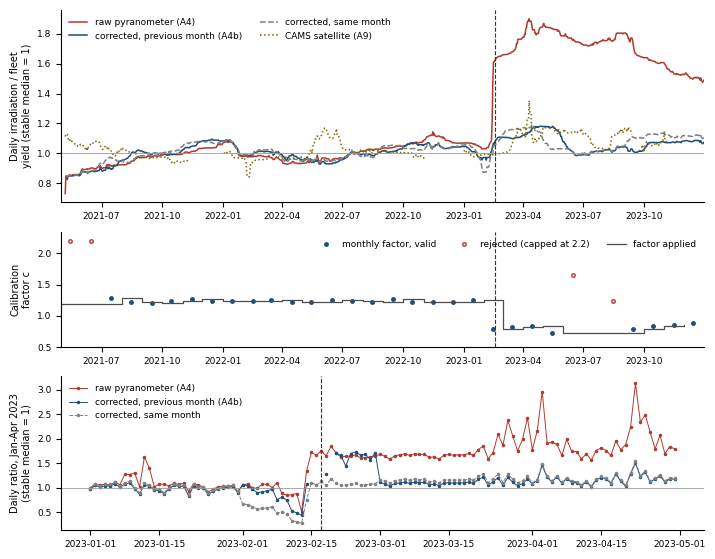

In [7]:
import matplotlib.pyplot as plt
A._style()
sd = pd.read_csv(C.RESULTS / 'nb1_audit' / 'sensor_daily.csv', parse_dates=['day']).set_index('day')
dkey = slots.normalize()
full_day = G15.notna().groupby(dkey).sum() >= 0.9 * 48
daily = (G15.groupby(dkey).sum() * 0.25 / 1000).where(full_day)      # kWh/m2 over the panel slots
ratio = daily.div(sd['fleet_yield_h'].reindex(daily.index), axis=0)
ratio_n = ratio / ratio.loc[:BOUNDARY - pd.Timedelta(days=1)].median()
daily_tab = pd.concat([daily.add_prefix('kWh_m2_'), ratio.add_prefix('ratio_fleet_'),
                       dd[['kt_sensor', 'dead']].reindex(daily.index), no['offset'].reindex(daily.index).rename('night_offset')], axis=1)
daily_tab['drifted'] = daily_tab.index >= BOUNDARY
daily_tab = daily_tab.rename_axis('day').reset_index()
sty = {'sensor_raw': ('#b03a2e', '-', 'raw pyranometer (A4)'), 'sensor_corr': ('#1f4e79', '-', 'corrected, previous month (A4b)'),
       'sensor_same': ('0.5', '--', 'corrected, same month'), 'cams': ('#7d6608', ':', 'CAMS satellite (A9)')}
f5, ax = plt.subplots(3, 1, figsize=(7.2, 5.6), gridspec_kw={'height_ratios': [2, 1.2, 1.6]})
for src, (c, ls, lab) in sty.items():
    r = ratio_n[src].reindex(pd.date_range(ratio_n.index.min(), ratio_n.index.max()))
    ax[0].plot(r.rolling('30D', center=True, min_periods=10).median(), color=c, ls=ls, lw=1.1, label=lab)
ax[0].axhline(1, color='0.6', lw=0.6)
ax[0].set_ylabel('Daily irradiation / fleet\nyield (stable median = 1)'); ax[0].legend(frameon=False, ncol=2, loc='upper left')
ms = pd.PeriodIndex(cal.index, freq='M').to_timestamp()
v = cal['valid'].to_numpy()
ax[1].plot(ms[v] + pd.Timedelta(days=14), cal['c_month'][v], 'o', ms=2.5, color='#1f4e79', label='monthly factor, valid')
ax[1].plot(ms[~v] + pd.Timedelta(days=14), cal['c_month'].clip(upper=2.2)[~v], 'o', ms=2.5, mfc='none', color='#b03a2e', label='rejected (capped at 2.2)')
ax[1].step(ms, cal['c_applied'], where='post', color='0.3', lw=0.9, label='factor applied')
ax[1].set_ylabel('Calibration\nfactor c'); ax[1].set_ylim(0.5, 2.35); ax[1].legend(frameon=False, ncol=3, loc='upper right')
for a_ in ax[:2]:
    a_.set_xlim(pd.Timestamp('2021-05-01'), pd.Timestamp('2023-12-31')); a_.axvline(BOUNDARY, color='0.2', ls='--', lw=0.8)
z0, z1 = pd.Timestamp('2023-01-01'), pd.Timestamp('2023-04-30')
for src in ['sensor_raw', 'sensor_corr', 'sensor_same']:
    c, ls, lab = sty[src]; r = ratio_n.loc[z0:z1, src]
    ax[2].plot(r.index, r, marker='.', ms=3, ls=ls, lw=0.7, color=c, label=lab)
ax[2].axvline(BOUNDARY, color='0.2', ls='--', lw=0.8); ax[2].axhline(1, color='0.6', lw=0.6)
ax[2].set_ylabel('Daily ratio, Jan-Apr 2023\n(stable median = 1)'); ax[2].legend(frameon=False, loc='upper left')
f5.tight_layout()
post = ratio_n.loc[BOUNDARY:]
print('median normalised daily ratio after the boundary:', post.median().round(3).to_dict())
print('... in the rest of the boundary month and the next month:', ratio_n.loc[BOUNDARY:(BOUNDARY + pd.offsets.MonthEnd(2))].median().round(3).to_dict())

## Outputs (all-or-nothing)

In [8]:
sensor_cfg = {
    'builds_on_frozen_part1': nb3['frozen1_sha256'],
    'time_base': {'sensor_lag_min': LAG_S, 'cams_lag_min': LAG_C,
                  'method': 'peak correlation of within-day 5-min changes with the NB2 fleet index, all days, whole minutes'},
    'bsrn': {'lower_W_m2': S.BSRN_LOWER, 'lower_on': 'raw reading', 'upper': '1.2 S0 cos(z)^1.2 + 50', 'upper_on': 'calibrated value'},
    'night_offset': {'elevation_below_deg': S.NIGHT_ELEVATION, 'window_days': S.NIGHT_WINDOW_DAYS, 'min_minutes': S.NIGHT_MIN_MINUTES},
    'dead_day': {'kt_below': S.DEAD_KT, 'min_minutes_elevation_10': S.DEAD_MIN_MINUTES},
    'clear_sky_detection': 'pvlib detect_clearsky defaults, one calendar month per call',
    'calibration': {'max_zenith_deg': S.CAL_MAX_ZENITH, 'min_clear_minutes': S.CAL_MIN_CLEAR, 'bounds': list(S.CAL_BOUNDS),
                    'applied': 'latest valid earlier month', 'sensitivity': 'same month'},
    'slots': {'min_minutes': S.SLOT_MIN_MINUTES, 'k_bounds_except_raw': list(C.K_BOUNDS), 'issue_min_gtilde': C.ISSUE_MIN_GTILDE},
    'external_gains': {'grid': [0.3, 3.0, 0.005], 'k_min': K_MIN, 'renormalised': False, 'prior_variant': PRIOR,
                       'G0': 'median donor gain'},
    'cams': {'reliability_min': 1.0, 'clear_sky_reference': 'Ineichen (as the fleet index)'},
}
SENSOR_TEXT = yaml.safe_dump(sensor_cfg, sort_keys=True)
SENSOR_HASH = hashlib.sha256(SENSOR_TEXT.encode()).hexdigest()
pre, postb = cal.index < BOUNDARY.strftime('%Y-%m'), cal.index > BOUNDARY.strftime('%Y-%m')
summary = {'notebook': 'NB4_sensor_baselines', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
           'frozen1_sha256': nb3['frozen1_sha256'], 'sensor_config_sha256': SENSOR_HASH,
           'lag_sensor_min': LAG_S, 'lag_cams_min': LAG_C, 'lag_peaks': lag_tab.round(3).to_dict(),
           'lag_peak_corr': {'sensor': pk(scan_s), 'cams': pk(scan_c)},
           'clear_day_corr_range_by_year': cds.groupby('year')['corr'].agg(['min', 'max']).round(5).to_dict('index'),
           'dead_days': {'n': int(len(dead_list)), 'first': str(dead_list.min().date()), 'last': str(dead_list.max().date()), 'outside_mar_may_2021': outside},
           'calibration': {'valid_months': int(cal['valid'].sum()), 'months': int(len(cal)),
                           'rejected': cal.index[~cal['valid'].to_numpy()].tolist(),
                           'c_valid_range_before_boundary': [float(cal.loc[pre & cal.valid, 'c_month'].min()), float(cal.loc[pre & cal.valid, 'c_month'].max())],
                           'c_valid_range_after_boundary': [float(cal.loc[postb & cal.valid, 'c_month'].min()), float(cal.loc[postb & cal.valid, 'c_month'].max())]},
           'above_limit_minutes': {'raw_reading': int(qc['n_above_limit_raw_reading'].sum()), 'calibrated': int(qc['n_above_upper_limit'].sum())},
           'coverage': cov.set_index('source').round(4).to_dict('index'),
           'gain_check_mismatches': int(mism), 'gain_check_event': chk_ev,
           'nb3_reproduction_max_abs_diff': float(max(repro)),
           'validation_median_nrmse0': vt.round(6).to_dict('index'),
           'agreement_median_by_period': {f'{s}|{q}': r for (s, q), r in at.round(4).to_dict('index').items()},
           'post_boundary_median_ratio': post.median().round(4).to_dict()}
tables = {'lag_scan_sensor': scan_s, 'lag_scan_cams': scan_c, 'lag_peaks': lag_tab.rename_axis('period').reset_index(),
          'clear_day_scan': cds, 'calibration_monthly': cal.rename_axis('month').reset_index(), 'qc_monthly': qc,
          'night_offset_daily': no.rename_axis('day').reset_index(), 'dead_days': dd.loc[dd['dead']].rename_axis('day').reset_index(),
          'coverage': cov, 'gains_external': gains_ext, 'priors_external': pri_ext, 'validation_sources': val_src,
          'agreement_events': agree, 'daily_sensor': daily_tab}
pq = {'index15': pd.concat([K.add_prefix('k_'), G15.add_prefix('G_'), pd.DataFrame({f'n_{s}': agg[s]['n'] for s in S.SOURCES})], axis=1).rename_axis('time').reset_index(),
      'sensor1min': pd.DataFrame({'time': grid, 'G_raw': G.to_numpy(), 'G_corr': G_corr.to_numpy(), 'G_same': G_same.to_numpy(),
                                  'flag': fl, 'clear': clear, 'G_cams': G_cams.to_numpy()})}
out = A.write_outputs('nb4_sensor', tables, summary, {'fig_sensor_correction': f5}, parquet=pq,
                      texts={'sensor_config.yaml': SENSOR_TEXT})
print('sensor config sha256:', SENSOR_HASH)
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

sensor config sha256: 4c47bfac9fa359fe0776925498b3d7328607c312be359b12d92f32198f49e79d
written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb4_sensor | ['agreement_events.csv', 'calibration_monthly.csv', 'clear_day_scan.csv', 'coverage.csv', 'daily_sensor.csv', 'dead_days.csv', 'figures', 'gains_external.csv', 'index15.parquet', 'lag_peaks.csv', 'lag_scan_cams.csv', 'lag_scan_sensor.csv', 'night_offset_daily.csv', 'priors_external.csv', 'qc_monthly.csv', 'sensor1min.parquet', 'sensor_config.yaml', 'summary.json', 'validation_sources.csv']
